# Policy result loader

This notebook opens an existing policy result store, dispatches to the policy-specific formatter, and inspects the returned `xarray.Dataset`. Use the dropdown below to select a `.zarr` store under `artifacts/`, ordered by newest first.


## Imports + helpers

In [1]:
import json
import sys
from pathlib import Path

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from matplotlib.colors import TwoSlopeNorm

project_root = Path.cwd()
if not (project_root / "tasks").exists():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

try:
    import scienceplots  # noqa: F401
except ModuleNotFoundError:
    scienceplots = None
else:
    plt.style.use("science")
from tasks.policies import load_policy_results
from network_creation.plotting.plot_pair import plot_pair
from network_creation.stats.topology_welfare import normalized_welfare_per_topology
from matplotlib.colors import Normalize
import numpy as np
from scipy.optimize import curve_fit
from notebooks.utils.table_pretty_print import make_gt_tabs, default_style_gt_table
from IPython.display import display

project_root

PosixPath('/home/hdahmou/Network_creation')

In [2]:
def get_welfare_reference(benefit_to_cost_ratio, distance_discount, n):
    reference_welfare_func = lambda topology_class: normalized_welfare_per_topology(
        topology_class=topology_class,
        n=n,
        benefit_to_cost_ratio=benefit_to_cost_ratio,
        distance_discount=distance_discount,
    )
    reference_welfare_max = reference_welfare_func("max")
    reference_welfare = {
        "star": float(reference_welfare_func("star") / reference_welfare_max),
        "empty": float(reference_welfare_func("empty") / reference_welfare_max),
        "random": float(reference_welfare_func("random") / reference_welfare_max),
    }
    return reference_welfare

In [3]:
def estimate_k_and_plateau(values_timeseries: np.ndarray):
    def exp_rise_from_zero(t, A, k):
        return A * (1 - np.exp(-k * t))

    N, nt = values_timeseries.shape
    t = np.arange(nt, dtype=float)
    A_vals = np.full(N, np.nan)
    k_vals = np.full(N, np.nan)

    for i in range(N):
        y = values_timeseries[i]
        finite = np.isfinite(y)
        if finite.sum() < 3:
            continue
        x = t[finite]
        yy = y[finite]
        A0 = np.nanmax(yy)
        k0 = 0.1
        popt, _ = curve_fit(
            exp_rise_from_zero,
            x,
            yy,
            p0=[A0, k0],
            bounds=([-np.inf, 0], [1, np.inf]),
            maxfev=10000,
        )
        A_vals[i], k_vals[i] = popt

    return A_vals, k_vals

In [4]:
rng = np.random.default_rng(42)

## Load and transform policy results


In [5]:
result_store_candidates = sorted(
    project_root.glob("artifacts/**/*.zarr"),
    key=lambda path: path.stat().st_mtime,
    reverse=True,
)
if not result_store_candidates:
    raise FileNotFoundError("No .zarr result stores found under artifacts/")

result_store_selector = widgets.Dropdown(
    options=[str(path.relative_to(project_root)) for path in result_store_candidates],
    value=str(result_store_candidates[0].relative_to(project_root)),
    description="Result:",
    layout=widgets.Layout(width="95%"),
)
display(result_store_selector)

Dropdown(description='Result:', layout=Layout(width='95%'), options=('artifacts/simulation_runs/run-20260430T1…

In [6]:
result_store_path = project_root / result_store_selector.value

ds = load_policy_results(result_store_path)
config = json.loads(Path(ds.attrs["config_path"]).read_text(encoding="utf-8"))

In [7]:
proportion_dims = tuple(dim for dim in ds["x"].dims if dim.endswith("_proportion"))
if len(proportion_dims) != 1:
    raise ValueError(
        f"Expected one policy-proportion dimension, found {proportion_dims}"
    )
policy_proportion_dim = proportion_dims[0]

result_store_path = Path(ds.attrs["result_store_path"])
config_path = Path(ds.attrs["config_path"])


def join_values(values, *, fmt=str):
    return ", ".join(fmt(v) for v in values)


def format_dims(dims):
    return " × ".join(str(dim) for dim in dims)


def format_shape(shape):
    return " × ".join(str(size) for size in shape)


array_roles = {
    "theta": "input parameter grid",
    "prior_low": "parameter lower bounds",
    "prior_high": "parameter upper bounds",
    "x": "observable time series",
}

In [8]:
run_summary_tabs = make_gt_tabs(
    [
        {
            "name": "Run",
            "value": {
                "run_id": result_store_path.stem,
                "result_store": str(result_store_path.relative_to(project_root)),
                "config": str(config_path.relative_to(project_root)),
                "failed_rows_present": bool(ds.attrs.get("has_failures", False)),
                "policy_mix_axis": policy_proportion_dim,
            },
        },
        {
            "name": "Run grid",
            "value": {
                "agent_counts": join_values(
                    ds.coords["n_agents"].values, fmt=lambda v: str(int(v))
                ),
                "policy_mix_values": join_values(
                    ds.coords[policy_proportion_dim].values,
                    fmt=lambda v: f"{float(v):.3g}",
                ),
                "parameter_samples_per_mix": int(ds.sizes["parameter_row"]),
                "total_dense_cells": int(
                    ds.sizes["n_agents"]
                    * ds.sizes[policy_proportion_dim]
                    * ds.sizes["parameter_row"]
                ),
                "time_steps": int(ds.sizes["step"]),
                "output_observables": join_values(ds.coords["observable"].values),
            },
        },
        {
            "name": "Arrays",
            "value": {
                name: {
                    "meaning": array_roles.get(name, "dataset variable"),
                    "axes": format_dims(value.dims),
                    "shape": format_shape(value.shape),
                }
                for name, value in ds.data_vars.items()
            },
        },
        {
            "name": "Dataset schema",
            "value": {
                "run_grid_axes": format_dims(
                    ("n_agents", policy_proportion_dim, "parameter_row")
                ),
                "time_series_axes": format_dims(ds["x"].dims),
                "parameter_axes": format_dims(ds["theta"].dims),
                "available_labels": join_values(ds.coords),
            },
        },
        {
            "name": "Parameter priors",
            "value": {
                str(name): {
                    "prior_low": float(low),
                    "prior_high": float(high),
                }
                for name, low, high in zip(
                    ds.coords["theta_parameter"].values,
                    ds["prior_low"].values,
                    ds["prior_high"].values,
                )
            },
        },
    ],
    gt_transform=default_style_gt_table,
    dict_key_col="field",
    dict_value_col="value",
)

display(run_summary_tabs)

## Plot per-step outputs


In [9]:
timeseries = ds["x"]
final = timeseries.isel(step=-1)
observables = tuple(ds.coords["observable"].values)
steps = ds.coords["step"].values
n_agents_values = ds.coords["n_agents"].values
proportion_values = ds.coords[policy_proportion_dim].values
parameter_rows = ds.coords["parameter_row"].values

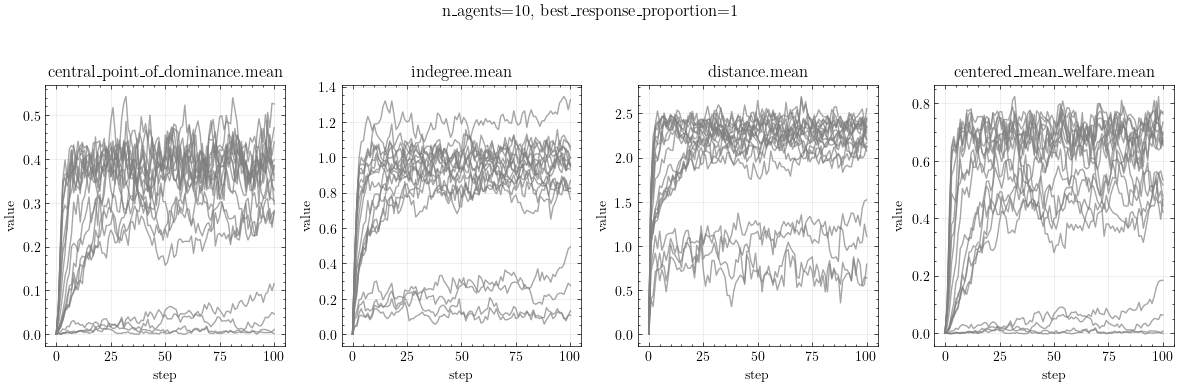

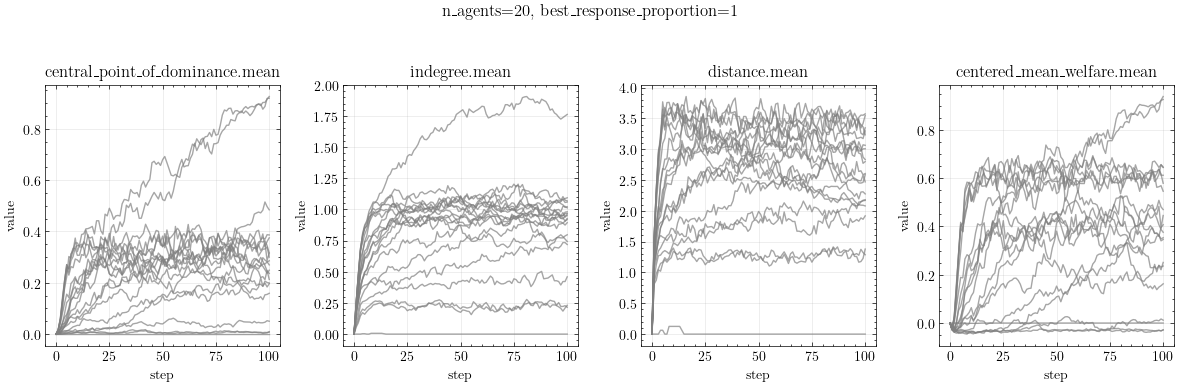

In [10]:
for selected_n_agents in n_agents_values:
    for selected_proportion in proportion_values:
        selector = {
            "n_agents": selected_n_agents,
            policy_proportion_dim: selected_proportion,
        }
        selected_timeseries = timeseries.sel(selector)
        row_values = selected_timeseries.values.reshape(
            selected_timeseries.sizes["parameter_row"],
            -1,
        )
        valid_positions = np.flatnonzero(np.isfinite(row_values).any(axis=1))
        if valid_positions.size == 0:
            continue

        fig, axes = plt.subplots(1, len(observables), figsize=(12, 4), sharex=True)
        axes = np.atleast_1d(axes)

        n_subset = min(20, valid_positions.size)
        chosen_positions = rng.choice(valid_positions, size=n_subset, replace=False)

        for observable_index, observable_name in enumerate(observables):
            series = selected_timeseries.sel(observable=observable_name)
            for row_position in chosen_positions:
                parameter_row = int(parameter_rows[row_position])
                axes[observable_index].plot(
                    steps,
                    series.isel(parameter_row=row_position).values,
                    alpha=0.7,
                    label=f"row={parameter_row}",
                    c="gray",
                )

            axes[observable_index].set_title(str(observable_name))
            axes[observable_index].set_xlabel("step")
            axes[observable_index].set_ylabel("value")
            axes[observable_index].grid(alpha=0.3)

        fig.suptitle(
            f"n_agents={int(selected_n_agents)}, "
            f"{policy_proportion_dim}={float(selected_proportion):.3g}"
        )
        plt.tight_layout(rect=(0, 0, 1, 0.94))
        plt.show()

## Pair plots


In [11]:
theta_labels = tuple(ds.coords["theta_parameter"].values)
observable_labels = tuple(ds.coords["observable"].values)
n_agents_values = ds.coords["n_agents"].values
proportion_values = ds.coords[policy_proportion_dim].values


def dense_selector(selected_n_agents, selected_proportion):
    return {
        "n_agents": selected_n_agents,
        policy_proportion_dim: selected_proportion,
    }


def selected_theta_and_final(selected_n_agents, selected_proportion):
    selector = dense_selector(selected_n_agents, selected_proportion)
    theta = ds["theta"].sel(selector).values
    final_values = ds["x"].isel(step=-1).sel(selector).values
    return theta, final_values


def finite_row_mask(theta, *arrays):
    mask = np.isfinite(theta).all(axis=1)
    for array in arrays:
        mask &= np.isfinite(array)
    return mask

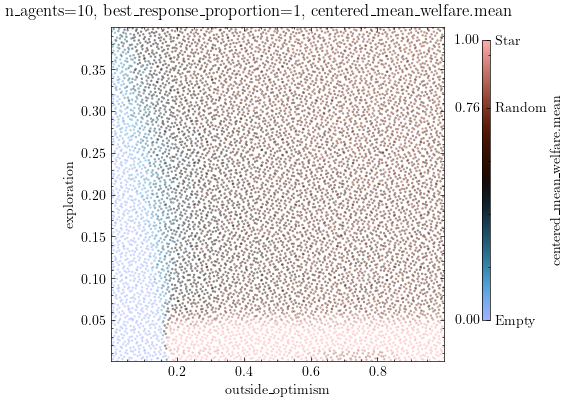

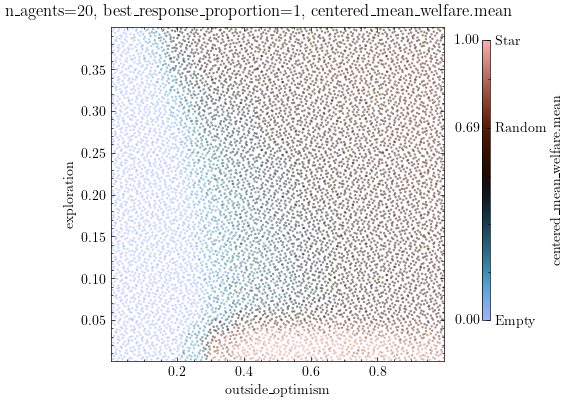

In [12]:
target_idx = -1

for selected_n_agents in n_agents_values:
    for selected_proportion in proportion_values:
        theta, final_values = selected_theta_and_final(
            selected_n_agents,
            selected_proportion,
        )
        target_values = final_values[:, target_idx]
        mask = finite_row_mask(theta, target_values)
        if not mask.any():
            continue
        theta = theta[mask]
        target_values = target_values[mask]

        benefit_to_cost_ratio = np.unique(
            theta[:, theta_labels.index("benefit_to_cost_ratio")]
        ).item()
        distance_discount = np.unique(
            theta[:, theta_labels.index("distance_discount")]
        ).item()

        reference_welfare = get_welfare_reference(
            benefit_to_cost_ratio=benefit_to_cost_ratio,
            distance_discount=distance_discount,
            n=int(selected_n_agents),
        )

        target_norm = TwoSlopeNorm(
            vmin=reference_welfare["empty"],
            vcenter=reference_welfare["random"],
            vmax=reference_welfare["star"],
        )

        fig, axes = plot_pair(
            X=theta,
            y=target_values,
            labels=theta_labels,
            label_y=observable_labels[target_idx],
            atol=1e-5,
            base_fig_size=4.0,
            cmap="berlin",
            method="points",
            resolution=100,
            sigma=2.5,
            # norm=target_norm,
            norm=Normalize(vmin=0.0, vmax=1.0),
            point_size=3,
            ordered_discrete_keys=["visibility_distance"],
        )

        cbar_ax = fig.axes[-1]
        vals = [
            reference_welfare["empty"],
            reference_welfare["random"],
            reference_welfare["star"],
        ]
        cbar_ax.set_yticks(vals, labels=["Empty", "Random", "Star"])
        cbar_ax.tick_params(labelright=True, labelleft=False)
        pos = cbar_ax.get_position()
        cbar_ax.set_position([pos.x0 + 0.04, pos.y0, pos.width, pos.height])
        for v in vals:
            cbar_ax.text(
                -0.35,
                v,
                f"{v:.2f}",
                transform=cbar_ax.get_yaxis_transform(),
                ha="right",
                va="center",
            )

        fig.suptitle(
            f"n_agents={int(selected_n_agents)}, "
            f"{policy_proportion_dim}={float(selected_proportion):.3g}, "
            f"{observable_labels[target_idx]}"
        )

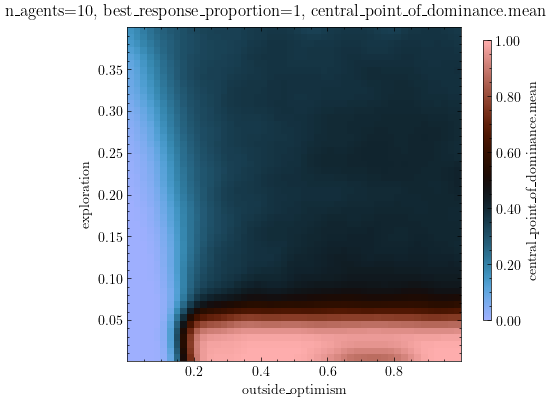

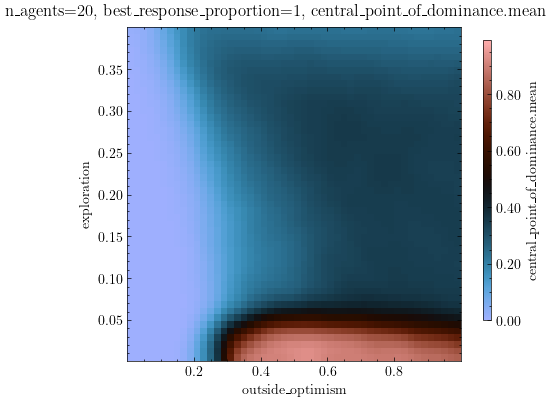

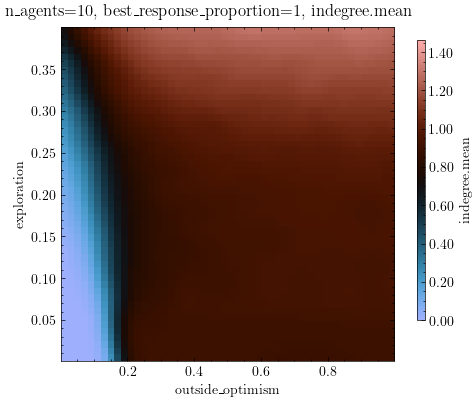

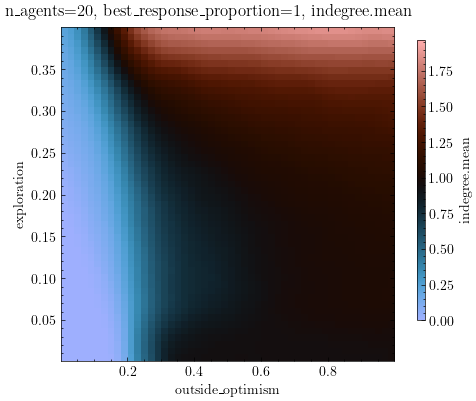

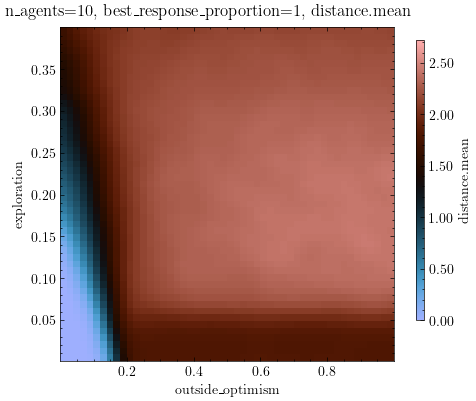

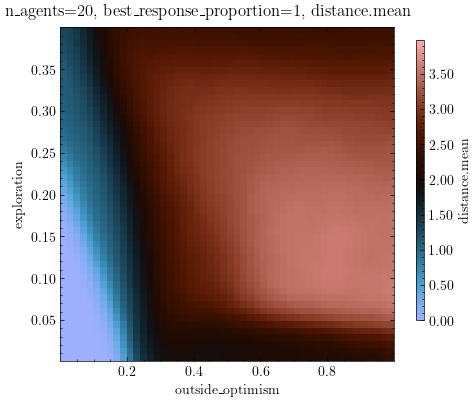

In [13]:
for target_idx in range(len(observable_labels) - 1):
    for selected_n_agents in n_agents_values:
        for selected_proportion in proportion_values:
            theta, final_values = selected_theta_and_final(
                selected_n_agents,
                selected_proportion,
            )
            target_values = final_values[:, target_idx]
            mask = finite_row_mask(theta, target_values)
            if not mask.any():
                continue
            fig, axes = plot_pair(
                X=theta[mask],
                y=target_values[mask],
                labels=theta_labels,
                label_y=observable_labels[target_idx],
                atol=1e-5,
                base_fig_size=4.0,
                cmap="berlin",
                method="gaussian",
                resolution=50,
                # sigma=0.1,
                point_size=3,
                ordered_discrete_keys=["visibility_distance"],
            )
            fig.suptitle(
                f"n_agents={int(selected_n_agents)}, "
                f"{policy_proportion_dim}={float(selected_proportion):.3g}, "
                f"{observable_labels[target_idx]}"
            )

# Convergence speed


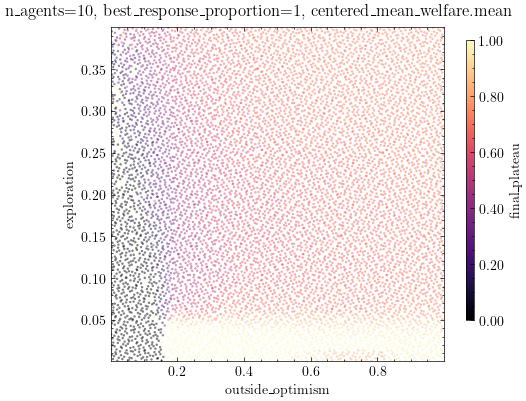

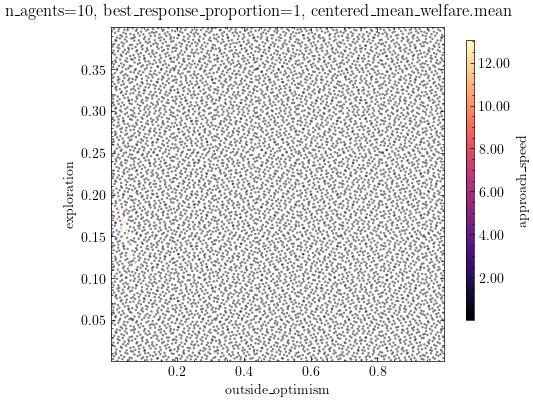

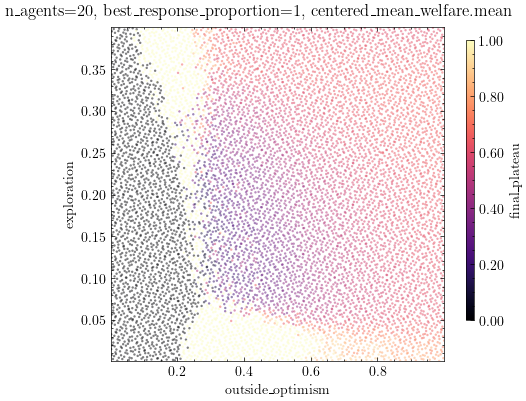

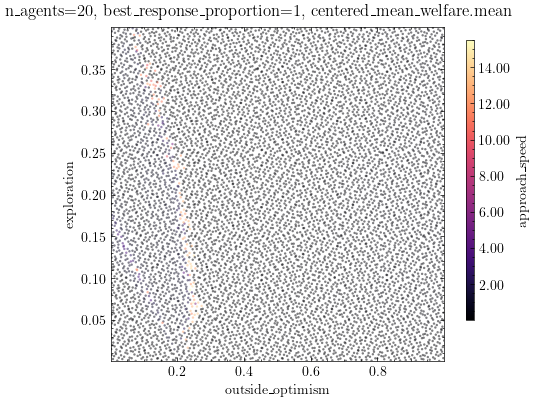

In [14]:
target_idx = -1
for selected_n_agents in n_agents_values:
    for selected_proportion in proportion_values:
        selector = dense_selector(selected_n_agents, selected_proportion)
        theta = ds["theta"].sel(selector).values
        selected_timeseries = (
            ds["x"].sel(selector).sel(observable=observable_labels[target_idx]).values
        )

        final_plateau, approach_speed = estimate_k_and_plateau(
            values_timeseries=selected_timeseries,
        )

        for y, target_label in zip(
            (final_plateau, approach_speed),
            ("final_plateau", "approach_speed"),
        ):
            mask = finite_row_mask(theta, y)
            if not mask.any():
                continue
            fig, axes = plot_pair(
                X=theta[mask],
                y=y[mask],
                labels=theta_labels,
                label_y=target_label,
                atol=1e-5,
                base_fig_size=4.0,
                cmap="magma",
                method="points",
                resolution=100,
                # sigma=2.5,
                point_size=3,
                norm=(
                    Normalize(vmin=0.0, vmax=1.0)
                    if target_label == "final_plateau"
                    else None
                ),
                ordered_discrete_keys=["visibility_distance"],
            )
            fig.suptitle(
                f"n_agents={int(selected_n_agents)}, "
                f"{policy_proportion_dim}={float(selected_proportion):.3g}, "
                f"{observable_labels[target_idx]}"
            )